# Feature selection and feature engineering: diagnosis

**Scope of this notebook (step 1).** Evidence only, nothing is changed in `config.yaml` yet. For each task it answers three questions on the **development set** (the locked test set is never touched):

1. **Redundancy** (section 1): which features carry the same information (Spearman clusters, VIF)?
2. **Relevance** (section 2): which features carry information about the target (mutual information)?
3. **Usefulness for the chosen model** (section 3): what happens to the temporal-CV score when a feature is shuffled (out-of-fold permutation importance)?

Section 4 merges the three into one table of **drop candidates**. They are candidates, not decisions: each one is confirmed or rejected afterwards by a paired ablation on the same temporal folds (`compare_preprocessing_variants` + `paired_comparison`), as in notebook 01, section 11.4.

**Reading rules**
- Mutual information and correlations are *descriptive*: they use all development rows at once, so they must not be used to pick features without the ablation.
- Permutation importance is computed **out of fold**: the model is fitted on the training rows of each temporal fold and the column is shuffled in the validation rows of that fold only.
- Features that are not in the current recipe (`margin`, `discount_rate`, ...) are included in sections 1 and 2 so they can be compared with the ones in use; section 3 only covers the features the recipe actually feeds to the model.

In [3]:
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.inspection import permutation_importance

from src.evaluate import select_scoring, temporal_folds
from src.pipeline import build_pipeline, prepare_task_data
from src.tasks import TASKS, get_task

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg = config["data"]

SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}
SEED = config["preprocessing"].get("random_state", 42)

## 0. Data and per-task feature groups

`prepare_task_data` runs the same load, validate, clean and split steps as `main.py`, so `X_dev` already holds **every** column the cleaning step produces (including the ones the recipe does not use). Each task keeps its own development set: the regression one only has repeat purchasers.

In [4]:
data, folds = {}, {}
for task in TASKS:
    data[task] = prepare_task_data(config, task)
    dates = data[task]["extras_dev"][data_cfg["date_column"]]
    folds[task] = temporal_folds(dates, config["cv"]["n_splits"], config["cv"]["gap_days"])


def feature_groups(task):
    """Which columns of X_dev are categorical, numeric-like, and which ones the recipe uses."""
    recipe, X = data[task]["preprocessing_config"], data[task]["X_dev"]
    categorical = [c for c in X.columns if str(X[c].dtype) == "category"]
    numeric = [c for c in X.columns if c not in categorical]
    used = (recipe["numeric_features"] + recipe["categorical_features"]
            + list(recipe.get("flag_features", [])))
    return {"categorical": categorical, "numeric": numeric, "used": used, "recipe": recipe}


groups = {task: feature_groups(task) for task in TASKS}
summary = pd.DataFrame({
    task: {"dev rows": len(data[task]["X_dev"]), "temporal folds": len(folds[task]),
           "columns in X_dev": data[task]["X_dev"].shape[1], "columns used by the recipe": len(groups[task]["used"]),
           "numeric-like not used": len([c for c in groups[task]["numeric"] if c not in groups[task]["used"]]),
           "categorical not used": len([c for c in groups[task]["categorical"] if c not in groups[task]["used"]])}
    for task in TASKS})
display(summary)

,classification,regression
dev rows,5024,2659
temporal folds,5,5
columns in X_dev,47,47
columns used by the recipe,34,41
numeric-like not used,9,6
categorical not used,4,0


## 1. Redundancy

### 1.1 Spearman correlation clusters

Spearman (rank) correlation, because most money and count columns are heavily skewed. Features are grouped by average-linkage hierarchical clustering on `1 - |rho|`, cutting at `|rho| >= 0.90` on average. A cluster with more than one member is a group of near-duplicates: at most one (or a ratio of them) should be needed by a linear model.

In [5]:
RHO_CUT = 0.90


def numeric_frame(task):
    X, g = data[task]["X_dev"], groups[task]
    return X[g["numeric"]].astype("float64")


def correlation_clusters(task):
    Xn = numeric_frame(task)
    Xn = Xn.loc[:, Xn.nunique() > 1]                         # constants have no correlation
    rho = Xn.corr(method="spearman").fillna(0.0)
    dist = 1 - rho.abs().to_numpy()
    np.fill_diagonal(dist, 0.0)
    labels = hierarchy.fcluster(hierarchy.linkage(squareform(dist, checks=False), "average"),
                                t=1 - RHO_CUT, criterion="distance")
    return rho, pd.Series(labels, index=rho.index, name="cluster")


rho, cluster = {}, {}
for task in TASKS:
    rho[task], cluster[task] = correlation_clusters(task)
    sizes = cluster[task].map(cluster[task].value_counts())
    rows = []
    for label in sorted(cluster[task][sizes > 1].unique()):
        members = cluster[task][cluster[task] == label].index.tolist()
        sub = rho[task].loc[members, members].abs().to_numpy()
        rows.append({"cluster": label, "size": len(members),
                     "min |rho|": sub[np.triu_indices(len(members), 1)].min().round(3),
                     "in recipe": [m for m in members if m in groups[task]["used"]],
                     "not in recipe": [m for m in members if m not in groups[task]["used"]]})
    print(f"\n{task.upper()}: {len(rows)} clusters with more than one feature (|rho| >= {RHO_CUT})")
    display(pd.DataFrame(rows).set_index("cluster"))


CLASSIFICATION: 7 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
9,3,0.945,"[purchase_count_30d, spend_30d]",[spend_share_30d]
10,2,0.921,"[purchase_count_90d, spend_90d]",[]
12,2,0.921,"[prior_std_purchase_value, prior_max_purchase_...",[]
14,2,0.907,"[prior_purchase_count, prior_total_spend]",[]
15,2,0.904,"[spend_180d, spend_365d]",[]
18,2,0.902,[line_discount_total],[discount_rate]
19,2,0.942,[net_total],[margin]



REGRESSION: 4 clusters with more than one feature (|rho| >= 0.9)


,size,min |rho|,in recipe,not in recipe
cluster,,,,
4,2,0.939,[net_total],[margin]
9,2,0.902,"[spend_180d, spend_365d]",[]
16,3,0.893,"[purchase_count_30d, spend_30d]",[spend_share_30d]
19,2,0.916,"[prior_std_purchase_value, prior_max_purchase_...",[]


### 1.2 Strongest pairs

The clusters above can chain features together; the pairs below show the actual strength of each link.

In [6]:
def top_pairs(task, n=15):
    r = rho[task].abs()
    upper = r.where(np.triu(np.ones(r.shape, dtype=bool), 1)).stack()
    pairs = upper.sort_values(ascending=False).head(n).rename("|rho|").reset_index()
    pairs.columns = ["feature A", "feature B", "|rho|"]
    pairs["both in recipe"] = [a in groups[task]["used"] and b in groups[task]["used"]
                               for a, b in zip(pairs["feature A"], pairs["feature B"])]
    return pairs.round(3)


for task in TASKS:
    print(f"\n{task.upper()}")
    display(top_pairs(task))


CLASSIFICATION


,feature A,feature B,|rho|,both in recipe
0,purchase_count_30d,spend_30d,0.965,True
1,spend_30d,spend_share_30d,0.965,False
2,purchase_count_30d,spend_share_30d,0.945,False
3,net_total,margin,0.942,False
4,prior_std_purchase_value,prior_max_purchase_value,0.921,True
5,purchase_count_90d,spend_90d,0.921,True
6,prior_purchase_count,prior_total_spend,0.907,True
7,spend_180d,spend_365d,0.904,True
8,line_discount_total,discount_rate,0.902,False
9,prior_total_spend,spend_365d,0.898,True



REGRESSION


,feature A,feature B,|rho|,both in recipe
0,spend_30d,spend_share_30d,0.947,False
1,net_total,margin,0.939,False
2,net_total,total_tax,0.928,True
3,purchase_count_30d,spend_30d,0.925,True
4,prior_std_purchase_value,prior_max_purchase_value,0.916,True
5,spend_180d,spend_365d,0.902,True
6,purchase_count_180d,purchase_count_365d,0.898,True
7,purchase_count_30d,spend_share_30d,0.893,False
8,customer_tenure_days,years_as_customer,0.889,True
9,prior_total_spend,spend_365d,0.885,True


### 1.3 Variance inflation factor (features in the recipe)

VIF of feature *j* is `1 / (1 - R²_j)`, with R²_j from regressing it on all the others. It is the number that matters for **logistic regression and Ridge** (classification's current model): a VIF above 10 means the coefficient is poorly determined, even if prediction is fine. Trees and forests are not affected by collinearity in the same way. Median imputation and standardisation first, same as the recipe; the VIF comes from the diagonal of the inverse correlation matrix.

In [7]:
def vif_table(task):
    Xn = numeric_frame(task)
    cols = [c for c in groups[task]["recipe"]["numeric_features"] + list(groups[task]["recipe"].get("flag_features", []))
            if c in Xn.columns]
    Z = Xn[cols]
    Z = Z.fillna(Z.median())
    Z = Z.loc[:, Z.std() > 0]
    Z = (Z - Z.mean()) / Z.std()
    inv = np.linalg.pinv(np.corrcoef(Z.to_numpy(), rowvar=False))
    return pd.Series(np.diag(inv), index=Z.columns, name="VIF").sort_values(ascending=False)


vif = {task: vif_table(task) for task in TASKS}
for task in TASKS:
    print(f"\n{task.upper()}: {int((vif[task] > 10).sum())} of {len(vif[task])} features have VIF > 10, "
          f"{int((vif[task] > 5).sum())} have VIF > 5 (top 12 below)")
    display(vif[task].head(12).round(1).to_frame())


CLASSIFICATION: 7 of 28 features have VIF > 10, 15 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.2
purchase_count_365d,22.5
prior_std_purchase_value,19.8
prior_mean_purchase_value,19.5
purchase_count_90d,16.6
prior_max_purchase_value,12.2
spend_180d,10.7
spend_365d,8.9
prior_purchase_count,8.6
prior_total_spend,8.3



REGRESSION: 7 of 31 features have VIF > 10, 16 have VIF > 5 (top 12 below)


,VIF
purchase_count_180d,29.6
purchase_count_365d,21.8
prior_std_purchase_value,18.2
prior_mean_purchase_value,17.8
purchase_count_90d,16.5
prior_max_purchase_value,10.5
spend_180d,10.2
net_total,8.5
spend_365d,8.4
prior_purchase_count,8.2


## 2. Relevance: mutual information with the target

Mutual information captures non-linear dependence too. Numeric columns (median-imputed) use the k-nearest-neighbour estimator; categorical columns use their integer codes as discrete variables. Estimates are noisy on small samples (regression has fewer than 3,000 rows), so treat the ranking as a guide, and look at the gap to the `random_noise`-like level rather than at the exact order. To get that reference level, a **shuffled copy of the target** is scored too: any feature whose MI is not clearly above it carries no usable signal.

In [8]:
def mutual_information(task, seed=SEED):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    g = groups[task]
    num = X[g["numeric"]].astype("float64")
    num = num.fillna(num.median())
    cat = X[g["categorical"]].apply(lambda s: s.cat.codes if str(s.dtype) == "category" else s)
    frame = pd.concat([num, cat], axis=1)
    discrete = np.array([c in g["categorical"] for c in frame.columns])
    mi_function = mutual_info_classif if task == "classification" else mutual_info_regression
    kwargs = dict(discrete_features=discrete, random_state=seed)
    mi = pd.Series(mi_function(frame, y.to_numpy(), **kwargs), index=frame.columns)
    shuffled = np.random.default_rng(seed).permutation(y.to_numpy())
    floor = pd.Series(mi_function(frame, shuffled, **kwargs), index=frame.columns)
    return mi, floor


mi, mi_floor = {}, {}
for task in TASKS:
    mi[task], mi_floor[task] = mutual_information(task)
    print(f"{task}: MI of the shuffled target, max over features = {mi_floor[task].max():.4f}, "
          f"median = {mi_floor[task].median():.4f}")
for task in TASKS:
    print(f"\n{task.upper()}: top 12 features by mutual information")
    display(pd.DataFrame({"MI": mi[task], "in recipe": [c in groups[task]["used"] for c in mi[task].index]})
            .sort_values("MI", ascending=False).head(12).round(4))

classification: MI of the shuffled target, max over features = 0.0178, median = 0.0009
regression: MI of the shuffled target, max over features = 0.0395, median = 0.0019

CLASSIFICATION: top 12 features by mutual information


,MI,in recipe
prior_max_purchase_value,0.1525,True
prior_min_purchase_value,0.1479,True
purchase_count_365d,0.1141,True
purchase_count_180d,0.1078,True
purchase_count_90d,0.1020,True
prior_mean_gap_days,0.1007,True
spend_365d,0.0889,True
spend_180d,0.0820,True
prior_std_gap_days,0.0816,True
municipality,0.0809,False



REGRESSION: top 12 features by mutual information


,MI,in recipe
spend_365d,0.2990,True
prior_max_purchase_value,0.2952,True
prior_purchase_count,0.2450,True
municipality,0.2419,True
spend_180d,0.2372,True
prior_total_spend,0.2330,True
purchase_count_365d,0.2215,True
purchase_count_180d,0.2207,True
prior_std_purchase_value,0.2135,True
prior_mean_purchase_value,0.1987,True


## 3. Usefulness for the chosen model: out-of-fold permutation importance

For each temporal fold: fit the task's **current** pipeline (recipe + model from `config.yaml`) on the training rows, then shuffle one column at a time in the validation rows and measure how much the selection metric gets worse (5 repeats). The importance is expressed in the metric's own units (accuracy points for classification, RMSE in euros for regression), so a positive number means "the model needs this column". Shuffling is done on the **raw input columns**, so the encoder and the scaler are re-applied to the shuffled values, exactly as they would be on real data.

Only columns the recipe feeds to the model are shuffled: shuffling an unused column cannot change anything. The `spend_365d` missing indicator is created inside the pipeline from `spend_365d`, so its effect is part of that column's importance.

In [9]:
N_REPEATS = 5


def oof_permutation_importance(task):
    X, y = data[task]["X_dev"], data[task]["y_dev"]
    metric = config[task]["selection_metric"]
    scorer = SCORING[task][metric]
    recipe = groups[task]["recipe"]
    columns = [c for c in groups[task]["used"] if c in X.columns]
    per_fold = {}
    for k, (train, validation) in enumerate(folds[task], start=1):
        pipeline = build_pipeline(recipe, get_task(task).model.build_model(config[task]["model"]))
        pipeline.fit(X.iloc[train], y.iloc[train])
        result = permutation_importance(pipeline, X.iloc[validation], y.iloc[validation], scoring=scorer,
                                        n_repeats=N_REPEATS, random_state=SEED, n_jobs=1)
        # sklearn scorers are 'higher is better', so a positive drop means the column helped
        importance = pd.Series(result.importances_mean, index=X.columns)[columns]
        per_fold[f"fold_{k}"] = importance
    return pd.DataFrame(per_fold)


perm_folds = {task: oof_permutation_importance(task) for task in TASKS}
perm = {}
for task in TASKS:
    f = perm_folds[task]
    perm[task] = pd.DataFrame({"mean": f.mean(axis=1), "std_between_folds": f.std(axis=1, ddof=1),
                               "folds_positive": (f > 0).sum(axis=1)})
unit = {"classification": "accuracy points", "regression": "RMSE (euros)"}
for task in TASKS:
    print(f"\n{task.upper()}: importance in {unit[task]} (model: {config[task]['model']['type']}, "
          f"{len(folds[task])} folds)")
    display(perm[task].sort_values("mean", ascending=False).round(4).head(12))


CLASSIFICATION: importance in accuracy points (model: logistic_regression, 5 folds)


,mean,std_between_folds,folds_positive
purchase_count_90d,0.0771,0.0426,5
prior_purchase_count,0.0758,0.0423,5
prior_mean_purchase_value,0.0579,0.0244,5
purchase_count_365d,0.0488,0.0099,5
total_tax,0.0457,0.0239,5
spend_365d,0.0286,0.0235,5
prior_max_purchase_value,0.0242,0.0325,3
customer_tenure_days,0.0181,0.0264,4
net_total,0.0131,0.0074,5
prior_min_purchase_value,0.0115,0.0087,5



REGRESSION: importance in RMSE (euros) (model: random_forest, 5 folds)


,mean,std_between_folds,folds_positive
spend_365d,326.6421,553.2918,5
municipality,74.1356,80.4133,3
spend_90d,68.1844,40.3086,5
spend_180d,53.7612,72.0992,4
purchase_month,35.7260,43.8696,5
commercial_region,22.9784,39.9335,4
prior_mean_purchase_value,22.1409,91.8003,4
prior_total_spend,19.5178,29.9225,5
net_total,17.1993,10.6093,5
transport_method,13.9382,21.3137,4


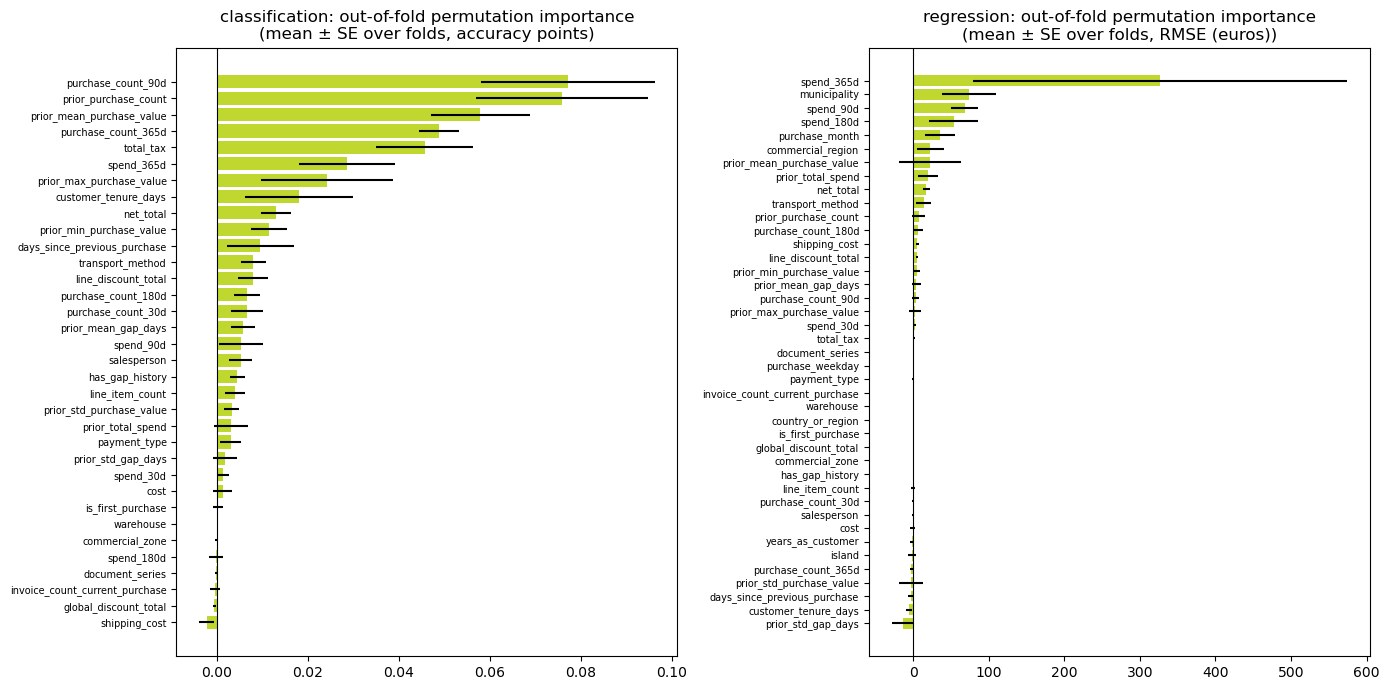

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, task in zip(axes, TASKS):
    p = perm[task].sort_values("mean")
    ax.barh(p.index, p["mean"], xerr=p["std_between_folds"] / np.sqrt(len(folds[task])), color="#BFD72F")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{task}: out-of-fold permutation importance\n(mean ± SE over folds, {unit[task]})")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

## 4. Drop candidates

One row per feature in the recipe, with the evidence side by side. A feature is flagged as a **drop candidate** when it satisfies **both**:

- *not useful*: mean permutation importance `<= 0`, or positive on at most 2 of the folds;
- *and* either *redundant* (it shares a Spearman cluster with another feature in the recipe) or *irrelevant* (MI not above the shuffled-target maximum).

The two-condition rule is deliberately strict: a single weak signal (for example a low importance on its own) is not enough to remove a column, because with 5 folds and a few thousand rows the importance of correlated features is split between them and each looks weaker than it is.

In [11]:
def candidate_table(task):
    g = groups[task]
    used = [c for c in g["used"] if c in perm[task].index]
    sizes = cluster[task].map(cluster[task].value_counts())
    in_recipe_in_cluster = {
        c: [m for m in cluster[task][cluster[task] == cluster[task].get(c)].index if m != c and m in g["used"]]
        for c in used if c in cluster[task].index}
    table = pd.DataFrame(index=used)
    table["VIF"] = vif[task].reindex(used)
    table["MI"] = mi[task].reindex(used)
    table["perm_mean"] = perm[task]["mean"]
    table["perm_folds_positive"] = perm[task]["folds_positive"]
    table["redundant_with"] = pd.Series({c: ", ".join(v) for c, v in in_recipe_in_cluster.items()})
    not_useful = (table["perm_mean"] <= 0) | (table["perm_folds_positive"] <= 2)
    redundant = table["redundant_with"].fillna("") != ""
    irrelevant = table["MI"] <= mi_floor[task].max()
    table["drop_candidate"] = not_useful & (redundant | irrelevant)
    return table.sort_values(["drop_candidate", "perm_mean"], ascending=[False, True])


candidates = {task: candidate_table(task) for task in TASKS}
for task in TASKS:
    t = candidates[task]
    print(f"\n{task.upper()}: {int(t['drop_candidate'].sum())} drop candidates out of {len(t)} features in the recipe")
    display(t.round(4).head(15))


CLASSIFICATION: 7 drop candidates out of 34 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
shipping_cost,1.1060,0.0000,-0.0022,1,,True
global_discount_total,1.0144,0.0093,-0.0005,0,,True
invoice_count_current_purchase,1.1156,0.0069,-0.0004,3,,True
document_series,NaN,0.0007,-0.0002,0,NaN,True
spend_180d,10.6634,0.0820,-0.0001,2,spend_365d,True
commercial_zone,NaN,0.0015,-0.0000,2,NaN,True
warehouse,NaN,0.0011,0.0000,0,NaN,True
is_first_purchase,3.0206,0.0183,0.0002,2,,False
cost,3.2667,0.0000,0.0013,3,,False
spend_30d,2.7632,0.0158,0.0014,4,purchase_count_30d,False



REGRESSION: 9 drop candidates out of 41 features in the recipe


,VIF,MI,perm_mean,perm_folds_positive,redundant_with,drop_candidate
prior_std_purchase_value,18.2094,0.2135,-2.5560,3,prior_max_purchase_value,True
cost,3.3988,0.0000,-0.7285,4,,True
purchase_count_30d,4.9868,0.0851,-0.3262,1,spend_30d,True
line_item_count,2.1267,0.0077,-0.3172,3,,True
has_gap_history,3.7850,0.0178,-0.0246,3,,True
commercial_zone,NaN,0.0057,-0.0165,2,NaN,True
global_discount_total,1.0315,0.0024,0.0000,1,,True
purchase_weekday,1.1923,0.0149,0.5326,2,,True
document_series,NaN,0.0169,0.6585,2,NaN,True
prior_std_gap_days,2.0945,0.1771,-13.7047,3,,False


### 4.1 A first engineering hint: the tax rate

`total_tax` is the 5th most important column for classification (more than `net_total`, which it is almost proportional to). A ratio of the two columns is the tax rate of the invoice; if it takes a handful of fixed values, those values behave like a categorical variable (VAT band, which depends on the product mix or the delivery region) that no current feature exposes directly.

In [12]:
X, y = data["classification"]["X_dev"], data["classification"]["y_dev"]
tax_rate = (X["total_tax"].astype("float64") / X["net_total"].astype("float64")).replace([np.inf, -np.inf], np.nan)
band = tax_rate.round(2).where(tax_rate.round(2).isin(tax_rate.round(2).value_counts().head(4).index), other=np.nan)
by_band = (pd.DataFrame({"band": band.fillna(-1), "repeat_purchase_90d": y})
           .groupby("band")["repeat_purchase_90d"].agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "repurchase_rate"}))
by_band.index = by_band.index.map(lambda v: "other" if v == -1 else f"{v:.2f}")
print(f"distinct tax rates (rounded to 2 decimals): {tax_rate.round(2).nunique()}")
display(by_band.round(3))

distinct tax rates (rounded to 2 decimals): 20


,rows,repurchase_rate
band,,
other,228,0.399
0.00,127,0.386
0.13,191,0.691
0.22,105,0.667
0.23,4373,0.553


## 5. What to do with this

1. **Redundancy and drop candidates** feed the in-pipeline `selection` step (variance threshold, L1 / forest-based selector, top-k) that is added to `build_pipeline`; the same candidates are also tested as a manual ablation (recipe minus the candidate group).
2. **Features worth engineering** are the ones whose information is spread over several correlated columns (the 30/90/180/365-day windows and the `prior_*` statistics): ratios and differences between them (trend, overdue ratio, frequency) are the first engineering candidates.
3. Every decision, kept or rejected, goes to `config.yaml` with a comment pointing to the section of this notebook, and to sections 5 and 12 of the README.

*Caveats: (a) permutation importance depends on the model in `config.yaml`; if change the final model, re-run this notebook. (b) With correlated features, the importance of a group is shared among its members, so the ablation is the arbiter, not this table.*